# Session 13: Correcting ERA5's humidity, and whether it changes the route

**Question:** Session 12 found that ERA5 is often just too dry to call ice-supersaturated air supersaturated. Does a simple correction find that air better on months it was never fitted to, and would routing with the correction choose different routes?

**Builds on:** Session 12 (ERA5 matched to 786,845 IAGOS measurements) and Session 8 (45 fixed routes on 24 nights of 2022).

**Related work** (from the published abstracts): Hildebrandt et al. (2026, [doi:10.5194/acp-26-6449-2026](https://doi.org/10.5194/acp-26-6449-2026)) compared ERA5 with IAGOS for 2011–2022 and found ETS 0.2–0.4, with lowered RHi thresholds (85–95%) improving detection. Antonopoulos et al. (2026, [doi:10.5194/acp-26-4771-2026](https://doi.org/10.5194/acp-26-4771-2026)) corrected ERA5 humidity with machine learning, raising ETS from 0.36 to 0.44. Driver et al. (2025, [doi:10.5194/acp-25-16411-2025](https://doi.org/10.5194/acp-25-16411-2025)) showed that the errors depend on the weather situation. This session does not try to beat those methods; it tests simple corrections on this project's region and data and asks the question they do not: does the correction change route decisions?

**Approach:**
1. Four ways of saying "ice-supersaturated" from ERA5 at a measured point:
   - **plain:** ERA5 RHi > 1 (what the project uses);
   - **fixed 0.97:** RHi > 0.97, pycontrails' default threshold (for this yes/no question its exponential humidity boost gives the same answer);
   - **fitted threshold:** RHi > t, t chosen for the best ETS;
   - **probability:** a logistic model of ERA5 RHi at the point and 150, 300 and 600 m above and below it, temperature and pressure, giving a probability, and a cut on it chosen for the best ETS.
2. Every fitted method is tested on months it was not fitted to (leave-one-month-out).
3. The 45 routes of Session 8 re-evaluated on all 24 nights with ERA5 humidity corrected by the fitted threshold, through the same pipeline (pycontrails' constant humidity scaling); route choices compared with plain ERA5.

**Rules fixed before any result was seen:**
- Points: the Session 12 height-test points (195–270 hPa, ERA5 available in all seven shifted fields); measured ice supersaturation as in Session 12.
- Thresholds from 0.80 to 1.00 in steps of 0.01; probability cuts from 0.05 to 0.95 in steps of 0.01; both chosen on the training months only, for the best ETS.
- Logistic regression with standardised features and a small ridge penalty (fixed, not tuned).
- Leave-one-month-out: each month is predicted by a fit to the other eleven.
- Scores with 95% intervals from resampling whole flights (1,000 resamples, seed 0); a method is called better than plain ERA5 only if the interval of its paired ETS difference excludes zero.
- Route decisions: the threshold fitted on all twelve months; the 45 routes (FL310–FL390), Session 8 fuel, 4 masses, λ = 0.1, 1 and 10; the deterministic rule (lowest fuel + λ × PCR km).

**Sections:** 1. Setup · 2. Data · 3. Four methods, tested on unseen months · 4. How trustworthy is the probability? · 5. Does the correction change the route? · 6. Figures · Results

## 1. Setup

Uses the Session 12 matched data (`iagos_data/matched`; set `IAGOS_DATA` to use another folder) and the cached ERA5 of the 24 study nights.

In [1]:
import os, sys, io, gc, time, warnings, contextlib
from pathlib import Path
SRC = (Path("..") / "src").resolve()
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pycontrails.models.humidity_scaling import ConstantHumidityScaling

from contrail_routing import config
from contrail_routing.met import load_era5_checked, load_region
from contrail_routing.evaluate import evaluate_routes, route_metrics
from contrail_routing.iagos import SHIFT_ORDER, observed_pcr, bootstrap_scores
from contrail_routing.calibration import (THRESHOLD_GRID, best_threshold, fit_logistic, predict_proba,
                                          leave_one_month_out, paired_ets_difference, brier, reliability)

warnings.filterwarnings("ignore", message=r"\s*Met data appears to have originated from ECMWF")
pd.set_option("display.width", 220)

DATA_DIR = Path(os.environ.get("IAGOS_DATA", Path.home() / "iagos_data"))
MATCHED = DATA_DIR / "matched"
results_dir = Path("..") / "results"
fig_dir, s8_dir, s13_dir = results_dir / "figures", results_dir / "session8", results_dir / "session13"
nights_dir = s13_dir / "nights"
nights_dir.mkdir(parents=True, exist_ok=True)

P_RANGE = (195.0, 270.0)
N_BOOT, SEED = 1000, 0
FIXED_THRESHOLD = 0.97
SEASON = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
          6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
FEATURES = [f"rhi_{s}" for s in SHIFT_ORDER] + ["T_base", "p_hPa"]
MASSES = ["light_56t", "model_default", "heavy_68t", "very_heavy_72t"]
LAMBDAS = [0.1, 1.0, 10.0]
DATES = config.STUDY_DATES
specs_all = config.route_specs(flight_levels=config.FLIGHT_LEVELS + [390])
print(f"IAGOS folder: {DATA_DIR} | {len(specs_all)} routes, {len(DATES)} nights")

IAGOS folder: C:\Users\barqb\iagos_data | 45 routes, 24 nights


## 2. Data

The Session 12 points with ERA5 in all seven fields (195–270 hPa). Measured ice supersaturation is recomputed exactly as in Session 12.

In [2]:
t0 = time.time()
points = pd.read_pickle(MATCHED / "iagos_points.pkl")
points = points[points["p_hPa"].between(*P_RANGE)]
era5 = pd.concat((pd.read_csv(f) for f in sorted((MATCHED / "era5").glob("*.csv"))), ignore_index=True)
df = points.merge(era5, on="point_id", how="inner", validate="one_to_one")
df = df.dropna(subset=FEATURES).reset_index(drop=True)
df = pd.concat([df, observed_pcr(df)], axis=1)
df["month"] = df["time"].dt.month
df["season"] = df["month"].map(SEASON)
for c in [f"rhi_{s}" for s in SHIFT_ORDER]:
    df[c] = df[c].clip(0.0, 2.0)
print(f"{len(df):,} points from {df['flight_id'].nunique()} flights in {time.time() - t0:.0f} s; "
      f"measured ice-supersaturated share {df['issr_obs'].mean():.3f}")
print("Points by month:", df["month"].value_counts().sort_index().to_dict())
same = (df["issr_base"] > 0.5) == (df["rhi_base"] > 1.0)
print(f"Plain ERA5 ISSR equals 'RHi > 1' at {same.mean():.4f} of points")

612,557 points from 810 flights in 15 s; measured ice-supersaturated share 0.117
Points by month: {1: 13977, 2: 22703, 3: 9379, 4: 5607, 5: 27421, 6: 35899, 7: 111341, 8: 95418, 9: 93786, 10: 29177, 11: 96270, 12: 71579}
Plain ERA5 ISSR equals 'RHi > 1' at 1.0000 of points


## 3. Four methods, tested on unseen months

For every month, the threshold and the logistic model are fitted on the other eleven months and applied to that month. Scores are pooled over all out-of-month predictions.

In [3]:
t0 = time.time()
cv, folds = leave_one_month_out(df, FEATURES, obs_col="issr_obs", score_col="rhi_base")
df = pd.concat([df, cv], axis=1)
df["pred_plain"] = (df["rhi_base"] > 1.0).astype(float)
df["pred_fixed"] = (df["rhi_base"] > FIXED_THRESHOLD).astype(float)
print(f"Leave-one-month-out done in {time.time() - t0:.0f} s")
print("\nFitted on the other months, per held-out month:")
print(folds.round(3).to_string(index=False))

METHODS = {"plain (RHi > 1)": "pred_plain", f"fixed (RHi > {FIXED_THRESHOLD})": "pred_fixed",
           "fitted threshold": "pred_thr", "probability": "pred_prob"}
rows = []
for name, col in METHODS.items():
    s = bootstrap_scores(df, "issr_obs", col, n_boot=N_BOOT, seed=SEED)
    d = paired_ets_difference(df, "issr_obs", "pred_plain", col, n_boot=N_BOOT, seed=SEED)
    rows.append({"method": name, **{k: s[k][0] for k in ("model_share", "hit_rate", "false_alarm_ratio", "ets")},
                 **{k + "_lo": s[k][1] for k in ("hit_rate", "false_alarm_ratio", "ets")},
                 **{k + "_hi": s[k][2] for k in ("hit_rate", "false_alarm_ratio", "ets")},
                 "ets_minus_plain": d[0], "diff_lo": d[1], "diff_hi": d[2]})
methods = pd.DataFrame(rows)
show = methods[["method", "model_share"]].copy()
for k in ("hit_rate", "false_alarm_ratio", "ets"):
    show[k] = [f"{r[k]:.2f} [{r[k + '_lo']:.2f}-{r[k + '_hi']:.2f}]" for _, r in methods.iterrows()]
show["ETS minus plain"] = [f"{r['ets_minus_plain']:+.3f} [{r['diff_lo']:+.3f} to {r['diff_hi']:+.3f}]"
                           for _, r in methods.iterrows()]
print(f"\nMeasured share {df['issr_obs'].mean():.3f}; {len(df):,} points, {df['flight_id'].nunique()} flights")
print(show.to_string(index=False))

by_season = pd.DataFrame({name: df.groupby("season").apply(
    lambda g, c=col: bootstrap_scores(g, "issr_obs", c, n_boot=200, seed=SEED)["ets"][0], include_groups=False)
    for name, col in METHODS.items()}).loc[["DJF", "MAM", "JJA", "SON"]]
print("\nETS by season (out-of-month predictions):")
print(by_season.round(3).to_string())
methods.to_csv(s13_dir / "method_scores.csv", index=False)
folds.to_csv(s13_dir / "fits_by_held_out_month.csv", index=False)
by_season.to_csv(s13_dir / "ets_by_season.csv")

Leave-one-month-out done in 9 s

Fitted on the other months, per held-out month:
 held_out_month  test_points  thr_fit  train_ets_thr  prob_cut  train_ets_prob
              1        13977     0.91          0.352      0.29           0.362
              2        22703     0.91          0.355      0.26           0.366
              3         9379     0.91          0.355      0.29           0.365
              4         5607     0.91          0.356      0.28           0.366
              5        27421     0.91          0.348      0.28           0.357
              6        35899     0.91          0.364      0.28           0.374
              7       111341     0.91          0.364      0.28           0.374
              8        95418     0.91          0.351      0.27           0.367
              9        93786     0.91          0.364      0.28           0.375
             10        29177     0.92          0.368      0.30           0.375
             11        96270     0.93          0.3

## 4. How trustworthy is the probability?

A probability is useful for routing only if it means what it says: of the points given 30%, about 30% should be supersaturated. Brier score = mean squared error of the probability (lower is better); the reference is the share measured in the other eleven months (no skill), and plain ERA5 as a 0/1 forecast.

In [4]:
rel = reliability(df["prob"], df["issr_obs"])
print("Reliability (out-of-month probabilities):")
print(rel.round(3).to_string())
clim = df["month"].map({m: df.loc[df["month"] != m, "issr_obs"].mean() for m in df["month"].unique()})
bs = {"probability": brier(df["prob"], df["issr_obs"]),
      "plain ERA5 as 0/1": brier(df["pred_plain"], df["issr_obs"]),
      "climatology (other months' share)": brier(clim, df["issr_obs"])}
print("\nBrier score:", {k: round(v, 4) for k, v in bs.items()},
      f"| skill vs climatology {1 - bs['probability'] / bs['climatology (other months\' share)']:.3f}")

full = fit_logistic(df[FEATURES].to_numpy(float), df["issr_obs"].to_numpy() > 0.5)
coef = pd.Series(full["beta"][1:], index=FEATURES, name="standardised coefficient")
print("\nLogistic model fitted on all months (standardised coefficients; larger = more influence):")
print(coef.round(3).to_string())
T_ALL, ets_all = best_threshold(df["rhi_base"], df["issr_obs"] > 0.5)
print(f"\nThreshold fitted on all twelve months (used for routes below): RHi > {T_ALL:.2f} "
      f"(in-sample ETS {ets_all:.3f}); range across the twelve folds: {folds['thr_fit'].min():.2f}-{folds['thr_fit'].max():.2f}")
rel.to_csv(s13_dir / "probability_reliability.csv")
coef.to_csv(s13_dir / "logistic_coefficients.csv")
pd.Series({**bs, "threshold_all_months": T_ALL}).to_csv(s13_dir / "probability_scores.csv")

Reliability (out-of-month probabilities):
               points  forecast  observed
bin                                      
(-0.001, 0.1]  439231     0.014     0.012
(0.1, 0.2]      42188     0.145     0.161
(0.2, 0.3]      28836     0.247     0.304
(0.3, 0.4]      25937     0.350     0.410
(0.4, 0.5]      25731     0.451     0.458
(0.5, 0.6]      25479     0.547     0.541
(0.6, 0.7]      17473     0.643     0.587
(0.7, 0.8]       6333     0.741     0.591
(0.8, 0.9]       1003     0.836     0.627
(0.9, 1.0]        346     0.931     0.341

Brier score: {'probability': 0.0687, 'plain ERA5 as 0/1': 0.1085, "climatology (other months' share)": 0.1037} | skill vs climatology 0.338

Logistic model fitted on all months (standardised coefficients; larger = more influence):
rhi_base       0.042
rhi_up150      0.557
rhi_down150    0.271
rhi_up300      0.619
rhi_down300    0.615
rhi_up600      0.306
rhi_down600    0.160
T_base        -0.314
p_hPa          0.443

Threshold fitted on all twelve m

## 5. Does the correction change the route?

The 45 routes of Session 8 on all 24 nights, with ERA5 humidity scaled so that RHi > T_ALL counts as supersaturated (pycontrails `ConstantHumidityScaling(rhi_adj=T_ALL)`), through the same pipeline. Fuel is unchanged (Session 8). For each night, mass and λ: the route chosen with plain ERA5 and with the corrected humidity, and how much contrail distance the plain choice flies through if the corrected humidity is right. The first check repeats one night without the correction and must reproduce Session 8 exactly.

In [5]:
pcr8 = pd.read_csv(s8_dir / "pcr_base_by_night.csv", index_col="route")
fuel8 = pd.read_csv(s8_dir / "fuel_by_night.csv")

def night_pcr(date, rhi_adj):
    path = nights_dir / f"{date}_rhi_adj_{rhi_adj:.2f}.csv"
    if path.exists():
        return pd.read_csv(path, index_col="route")["pcr_km"]
    met, _ = load_era5_checked((f"{date}T00", f"{date}T06"), config.LEVELS_FINE,
                               config.REGION_LON, config.REGION_LAT)
    region = load_region(met, config.REGION_LON, config.REGION_LAT)
    met.data.close()
    del met
    routes = config.build_routes(specs_all, departure=pd.Timestamp(f"{date} 00:00"))
    with contextlib.redirect_stdout(io.StringIO()):
        tables = evaluate_routes(routes, region, humidity_scaling=ConstantHumidityScaling(rhi_adj=rhi_adj))
    pcr = route_metrics(tables, specs_all).set_index("route")["pcr_km"]
    pcr.to_csv(path)
    gc.collect()
    return pcr

check = night_pcr("2022-03-01", 1.00)
d = (check - pcr8["2022-03-01"].reindex(check.index)).abs().max()
print(f"Check: 2022-03-01 with rhi_adj = 1.00 differs from Session 8 by at most {d:.2e} km")
assert d < 1e-6, "the route evaluation no longer reproduces Session 8"

t0 = time.time()
pcr_corr = {}
for i, date in enumerate(DATES, 1):
    pcr_corr[date] = night_pcr(date, T_ALL)
    print(f"[{i:2d}/{len(DATES)}] {date}: PCR km summed over the 45 routes, plain {pcr8[date].sum():8.0f} -> "
          f"corrected {pcr_corr[date].sum():8.0f}", flush=True)
pcr_corr = pd.DataFrame(pcr_corr)
print(f"Done in {(time.time() - t0) / 60:.1f} min")
pcr_corr.to_csv(s13_dir / "pcr_corrected_by_night.csv", index_label="route")

ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
Check: 2022-03-01 with rhi_adj = 1.00 differs from Session 8 by at most 2.27e-13 km
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 1/24] 2022-01-01: PCR km summed over the 45 routes, plain    30175 -> corrected    42809
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 2/24] 2022-01-15: PCR km summed over the 45 routes, plain     1787 -> corrected     2491
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 3/24] 2022-02-01: PCR km summed over the 45 routes, plain     6376 -> corrected    13938
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 4/24] 2022-02-15: PCR km summed over the 45 routes, plain      124 -> corrected     1256
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 5/24] 2022-03-01: PCR km summed over the 45 routes, 

In [6]:
rows = []
for (date, mc), g in fuel8[fuel8["feasible"]].groupby(["date", "mass_case"]):
    f = g.set_index("route")["fuel_kg"]
    plain, corr = pcr8.loc[f.index, date], pcr_corr.loc[f.index, date]
    for lam in LAMBDAS:
        r_plain = (f + lam * plain).idxmin()
        r_corr = (f + lam * corr).idxmin()
        J_corr = f + lam * corr
        rows.append({"date": date, "mass_case": mc, "lambda": lam, "route_plain": r_plain, "route_corrected": r_corr,
                     "changed": r_plain != r_corr,
                     "plain_choice_pcr_plain_km": plain[r_plain], "plain_choice_pcr_corrected_km": corr[r_plain],
                     "corrected_choice_pcr_corrected_km": corr[r_corr],
                     "extra_fuel_corrected_kg": f[r_corr] - f[r_plain],
                     "loss_if_corrected_true_kg": J_corr[r_plain] - J_corr[r_corr]})
dec = pd.DataFrame(rows)
dec["hidden_pcr_km"] = dec["plain_choice_pcr_corrected_km"] - dec["plain_choice_pcr_plain_km"]
print(f"Routes: total PCR km over all routes and nights, plain {pcr8[DATES].to_numpy().sum():,.0f} -> "
      f"corrected {pcr_corr[DATES].to_numpy().sum():,.0f} "
      f"({100 * (pcr_corr[DATES].to_numpy().sum() / pcr8[DATES].to_numpy().sum() - 1):+.0f}%)")
print(f"Route-nights with any PCR: plain {int((pcr8[DATES] > 0).to_numpy().sum())}, "
      f"corrected {int((pcr_corr[DATES] > 0).to_numpy().sum())} of {pcr_corr.size}")
summ = dec.groupby(["mass_case", "lambda"]).agg(
    nights=("changed", "size"), changed=("changed", "sum"),
    hidden_pcr_km_median=("hidden_pcr_km", "median"), hidden_pcr_km_max=("hidden_pcr_km", "max"),
    nights_with_hidden_pcr=("hidden_pcr_km", lambda x: int((x > 0.5).sum())),
    extra_fuel_kg_median=("extra_fuel_corrected_kg", "median"), extra_fuel_kg_max=("extra_fuel_corrected_kg", "max"),
    loss_kg_median=("loss_if_corrected_true_kg", "median"), loss_kg_max=("loss_if_corrected_true_kg", "max"))
print("\nPlain-ERA5 choice vs corrected choice (24 nights per row):")
print(summ.loc[MASSES].round(1).to_string())
print(f"\nCases where the choice changes: {int(dec['changed'].sum())} of {len(dec)}")
dec.to_csv(s13_dir / "decisions_plain_vs_corrected.csv", index=False)
summ.to_csv(s13_dir / "decisions_summary.csv")

Routes: total PCR km over all routes and nights, plain 220,506 -> corrected 356,228 (+62%)
Route-nights with any PCR: plain 616, corrected 706 of 1080

Plain-ERA5 choice vs corrected choice (24 nights per row):
                       nights  changed  hidden_pcr_km_median  hidden_pcr_km_max  nights_with_hidden_pcr  extra_fuel_kg_median  extra_fuel_kg_max  loss_kg_median  loss_kg_max
mass_case      lambda                                                                                                                                                        
light_56t      0.1         24        1                   0.0              248.4                       7                   0.0               33.0             0.0          0.1
               1.0         24        4                   0.0              524.4                       7                   0.0              271.9             0.0        409.2
               10.0        24        6                   0.0              690.0              

## 6. Figures

Left: ETS of the four methods on unseen months, with 95% intervals. Middle: reliability of the probability (out-of-month); the diagonal is perfect calibration. Right: for λ = 1, the contrail distance the plain-ERA5 choice flies through if the corrected humidity is right, on each night, by mass.

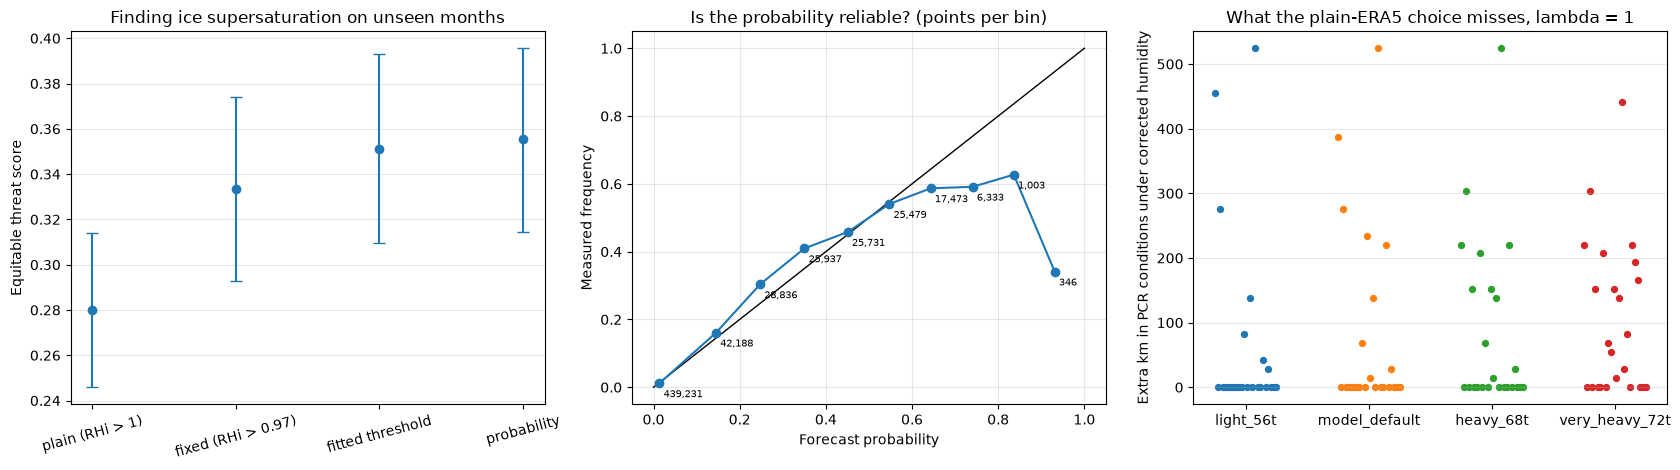

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ax = axes[0]
y = methods["ets"].to_numpy()
ax.errorbar(range(len(methods)), y, yerr=np.vstack([y - methods["ets_lo"], methods["ets_hi"] - y]),
            fmt="o", capsize=4)
ax.set_xticks(range(len(methods)))
ax.set_xticklabels(methods["method"], rotation=15)
ax.set_ylabel("Equitable threat score")
ax.set_title("Finding ice supersaturation on unseen months")
ax.grid(alpha=0.3, axis="y")

ax = axes[1]
ax.plot([0, 1], [0, 1], color="k", lw=1)
ax.plot(rel["forecast"], rel["observed"], "o-")
for _, r in rel.iterrows():
    ax.annotate(f"{int(r['points']):,}", (r["forecast"], r["observed"]), fontsize=7,
                xytext=(3, -10), textcoords="offset points")
ax.set_xlabel("Forecast probability")
ax.set_ylabel("Measured frequency")
ax.set_title("Is the probability reliable? (points per bin)")
ax.grid(alpha=0.3)

ax = axes[2]
d1 = dec[dec["lambda"] == 1.0]
for k, mc in enumerate(MASSES):
    v = d1.loc[d1["mass_case"] == mc, "hidden_pcr_km"].to_numpy()
    ax.scatter(np.full(len(v), k) + np.linspace(-0.25, 0.25, len(v)), v, s=18)
ax.set_xticks(range(len(MASSES)))
ax.set_xticklabels(MASSES)
ax.set_ylabel("Extra km in PCR conditions under corrected humidity")
ax.set_title("What the plain-ERA5 choice misses, lambda = 1")
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(fig_dir / "session13_correcting_humidity.png", dpi=150, bbox_inches="tight")
plt.show()

## Results

### Setup

612,557 IAGOS points from 810 flights at 195–270 hPa (the Session 12 height-test points); 11.7% measured as ice-supersaturated. Four ways of calling a point ice-supersaturated from ERA5 were compared: plain ERA5 (RHi > 1), the fixed pycontrails threshold (RHi > 0.97), a fitted threshold, and a calibrated probability from a logistic model. Every fitted method was tested on months it was not fitted to (leave-one-month-out). The 45 routes of Session 8 were then re-evaluated on all 24 nights with ERA5 humidity corrected by the threshold fitted on all twelve months.

### Checks

- **Plain ERA5 is what the project uses:** pycontrails' ice supersaturation equals "RHi > 1" at every point.
- **The corrected route evaluation reproduces Session 8** when the correction is switched off: 2022-03-01 with rhi_adj = 1.00 differs by at most 2.3 × 10⁻¹³ km.
- **The fitted threshold is stable:** 0.91 when fitted without each of 10 of the 12 months, 0.92 without October and 0.93 without November; the probability cut is 0.26–0.30. The training-month ETS (0.34–0.38) is close to the unseen-month ETS below, so the fits are not overfitted.
- **Deviations from the rules fixed in advance:** none.

### Findings

#### 1. A simple threshold finds far more of the ice-supersaturated air, at a small cost in false alarms

Scores on unseen months, with 95% intervals from resampling whole flights. "ETS minus plain" is a paired comparison on the same points:

| Method | ERA5 share | Hit rate | False alarm ratio | ETS | ETS minus plain |
|---|---|---|---|---|---|
| plain (RHi > 1) | 0.10 | 0.46 [0.42–0.50] | 0.46 [0.40–0.52] | 0.28 [0.25–0.31] | — |
| fixed (RHi > 0.97) | 0.13 | 0.60 [0.55–0.64] | 0.47 [0.41–0.53] | 0.33 [0.29–0.37] | +0.053 [+0.038 to +0.071] |
| fitted threshold (≈ 0.91) | 0.17 | 0.71 [0.67–0.75] | 0.50 [0.45–0.55] | 0.35 [0.31–0.39] | +0.071 [+0.049 to +0.096] |
| probability | 0.18 | 0.74 [0.70–0.78] | 0.51 [0.46–0.56] | 0.36 [0.31–0.40] | +0.075 [+0.052 to +0.102] |

- **All three corrections beat plain ERA5,** with intervals that exclude zero. The fitted threshold finds 71% of the measured ice-supersaturated air instead of 46%, while the false alarm ratio rises only from 0.46 to 0.50.
- **The fitted threshold, about 0.91, sits inside the 85–95% range** that Hildebrandt et al. (2026) found improves ERA5's detection over 2011–2022. That is an independent agreement.
- **The logistic model is not clearly better than the fitted threshold** for the yes/no question (ETS 0.36 against 0.35; gains over plain +0.075 against +0.071). The extra complexity buys a usable probability (finding 2), not better yes/no answers.
- **Too much supersaturated air, by design.** Optimising ETS makes the corrected methods mark more air as supersaturated than was measured (17–18% against 11.7%). That trade of more hits for some more false alarms has to be remembered when the correction is used for routing.
- **Not uniform across seasons.** ETS by season, on unseen months:

| Season | plain | fixed 0.97 | fitted threshold | probability |
|---|---|---|---|---|
| Winter (DJF) | 0.41 | 0.43 | 0.43 | 0.39 |
| Spring (MAM) | 0.33 | 0.40 | 0.46 | 0.47 |
| Summer (JJA) | 0.27 | 0.31 | 0.31 | 0.29 |
| Autumn (SON) | 0.23 | 0.30 | 0.33 | 0.35 |

  In winter, plain ERA5 is already the most skilful and the corrections add little (the probability is slightly worse). The gains come in spring and autumn.

#### 2. The probability is reliable up to about 60%, and overconfident above that

| Forecast probability | 0–0.1 | 0.1–0.2 | 0.2–0.3 | 0.3–0.4 | 0.4–0.5 | 0.5–0.6 | 0.6–0.7 | 0.7–0.8 | 0.8–0.9 | 0.9–1 |
|---|---|---|---|---|---|---|---|---|---|---|
| Points | 439,231 | 42,188 | 28,836 | 25,937 | 25,731 | 25,479 | 17,473 | 6,333 | 1,003 | 346 |
| Mean forecast | 0.01 | 0.15 | 0.25 | 0.35 | 0.45 | 0.55 | 0.64 | 0.74 | 0.84 | 0.93 |
| Measured frequency | 0.01 | 0.16 | 0.30 | 0.41 | 0.46 | 0.54 | 0.59 | 0.59 | 0.63 | 0.34 |

- **Up to about 60% the probability means what it says.** Above that it is too confident: points given 70–90% were supersaturated about 60% of the time. Those points are only 1.3% of the total.
- **Brier score** (mean squared error; lower is better):
  - probability: 0.069;
  - simply predicting each month's share from the other months: 0.104;
  - plain ERA5 as a yes/no forecast: 0.109.
  
  So the probability has a skill of 0.34 over that climatology. Plain ERA5's confident yes/no answers score *worse* than the climatology on this measure.
- **What the model uses:** ERA5's humidity 150–300 m above and below the point carries more weight than the humidity at the point itself (standardised coefficients 0.27–0.62 against 0.04). Higher pressure (lower altitude) and colder air make supersaturation more likely. The humidity features are strongly correlated with each other, so the individual coefficients should not be read one at a time. Together they say that the vertical neighbourhood helps.

#### 3. With corrected humidity, about a quarter of route choices change

The 45 routes on 24 nights, ERA5 humidity scaled so that RHi > 0.91 counts as supersaturated (pycontrails `ConstantHumidityScaling(rhi_adj=0.91)`), fuel unchanged:

- **Contrail exposure rises sharply.** Contrail distance summed over all routes and nights rises by 62% (220,506 to 356,228 km), and it rises on every night. Route-nights with any PCR go from 616 to 706 of 1,080.
- **The deterministic choice (lowest fuel + λ × PCR km) changes in 79 of 288 cases,** more often for heavier aircraft and higher λ:

| Mass | λ = 0.1 | λ = 1 | λ = 10 |
|---|---|---|---|
| 56 t | 1 | 4 | 6 |
| ≈64 t | 5 | 6 | 8 |
| 68 t | 4 | 7 | 10 |
| 72 t | 6 | 11 | 11 |

- **The plain-ERA5 choice flies through contrail conditions it did not know about,** if the corrected humidity is right:
  - this happens on 7 of 24 nights at 56 t and on 11–17 nights at 72 t;
  - up to 248–690 km per flight;
  - medians of 41–83 km for 68–72 t at λ = 0.1 and 62 km for 72 t at λ = 1.
- **Switching to the corrected choice usually costs no extra fuel** (median 0 in every case; at most 21–36 kg at λ = 0.1, 154–272 kg at λ = 1 and 72–561 kg at λ = 10).
- **Measured in the corrected objective,** sticking with the plain choice loses up to 13.6 kg at λ = 0.1, up to 393–457 kg at λ = 1 and up to 3,833–4,396 kg fuel-equivalent at λ = 10, with a median of 0.

### What this means for the project

- **The humidity correction changes decisions, not only scores.** A one-number correction, fitted on measurements and stable across months, changes a quarter of route choices and reveals contrail exposure the plain plan misses. This turns Session 12's conclusion (humidity, more than height, is ERA5's weakness) into a decision result.
- **The probability is the better input for routing,** because it carries a calibrated chance instead of a hard yes/no, but only up to about 60% without recalibration. Session 14 can use it to plan routes on expected contrail distance, combined with the measured height-error weights from Session 12.

### Limitations

- The correction was fitted at 195–270 hPa (about FL340–FL390) and applied to all route levels (FL310–FL390); FL310–FL330 is an extrapolation.
- The corrected routes assume the corrected humidity is the truth. With ETS-optimal thresholds that overstates supersaturated air (17% against 11.7% measured), so the "hidden exposure" figures are an upper estimate.
- One threshold for all seasons and levels; the season table shows this is not ideal in winter. Region, year and the four IAGOS aircraft as in Session 12.
- The related-work figures come from the papers' abstracts. Their ETS values used other regions, periods and definitions, so they are context, not a like-for-like comparison.

### References and data

- Hildebrandt, K. G., Castino, F., Meijer, V., & Yin, F. (2026). Variability of ice supersaturated regions at flight altitudes: evaluation of ERA5 reanalysis using IAGOS in situ measurements. *Atmospheric Chemistry and Physics*. https://doi.org/10.5194/acp-26-6449-2026
- Antonopoulos, M., Juvin-Quarroz, J., & Boucher, O. (2026). Technical note: Hybrid machine learning model for bias correction of UTLS relative humidity against IAGOS observations in ERA5 reanalysis. *Atmospheric Chemistry and Physics*. https://doi.org/10.5194/acp-26-4771-2026
- Driver, O. G. A., Stettler, M. E. J., & Gryspeerdt, E. (2025). The ice supersaturation biases limiting contrail modelling are structured around extratropical depressions. *Atmospheric Chemistry and Physics*. https://doi.org/10.5194/acp-25-16411-2025
- Boulanger, D., Blot, R., Bundke, U., Gerbig, C., Hermann, M., Nédélec, P., Rohs, S., & Ziereis, H. (2018). IAGOS final quality controlled Observational Data L2 – Time series [Dataset]. Aeris. https://doi.org/10.25326/06 (CC BY 4.0; quality-filtered, cut to the study region and compared with ERA5; only summary tables are saved in the repository).

“MOZAIC/CARIBIC/IAGOS data were created with support from the European Commission, national agencies in Germany (BMBF), France (MESR), and the UK (NERC), and the IAGOS member institutions (http://www.iagos.org/partners). The participating airlines (Lufthansa, Air France, Austrian, China Airlines, Hawaiian Airlines, Air Canada, Iberia, Eurowings Discover, Cathay Pacific, Air Namibia, Sabena) supported IAGOS by carrying the measurement equipment free of charge since 1994. The data are available at http://www.iagos.fr thanks to additional support from AERIS.”